<div align="center">

# Assignment 4 — Naive Bayes

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 4 — Naive Bayes

**Dataset:** Wisconsin Breast Cancer (built into scikit-learn).

**Objective:** Classify tumours as **benign** or **malignant** using Naive Bayes, and compare NB variants.

## 1. Theory — Bayes' Theorem

$$P(y \mid X) = \frac{P(X \mid y)\,P(y)}{P(X)}$$

Naive Bayes assumes features are **conditionally independent** given the class ('naive' assumption). Despite this simplification it is fast, needs little data, and works well in practice.

Variants:
- **GaussianNB** — continuous features, models each class as a Gaussian
- **MultinomialNB** — count data (text, word counts)
- **BernoulliNB** — binary features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_curve, roc_auc_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

## 2. Load & Explore the Data

In [2]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['diagnosis'] = pd.Categorical.from_codes(cancer.target, cancer.target_names)
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [3]:
print('Shape:', df.shape)
df['diagnosis'].value_counts()

Shape: (569, 31)


diagnosis
benign       357
malignant    212
Name: count, dtype: int64

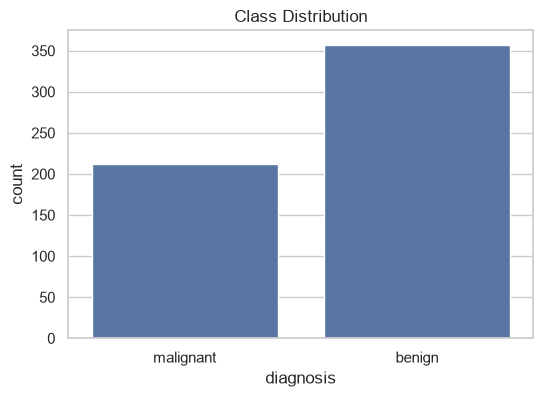

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x='diagnosis', data=df)
plt.title('Class Distribution')
plt.show()

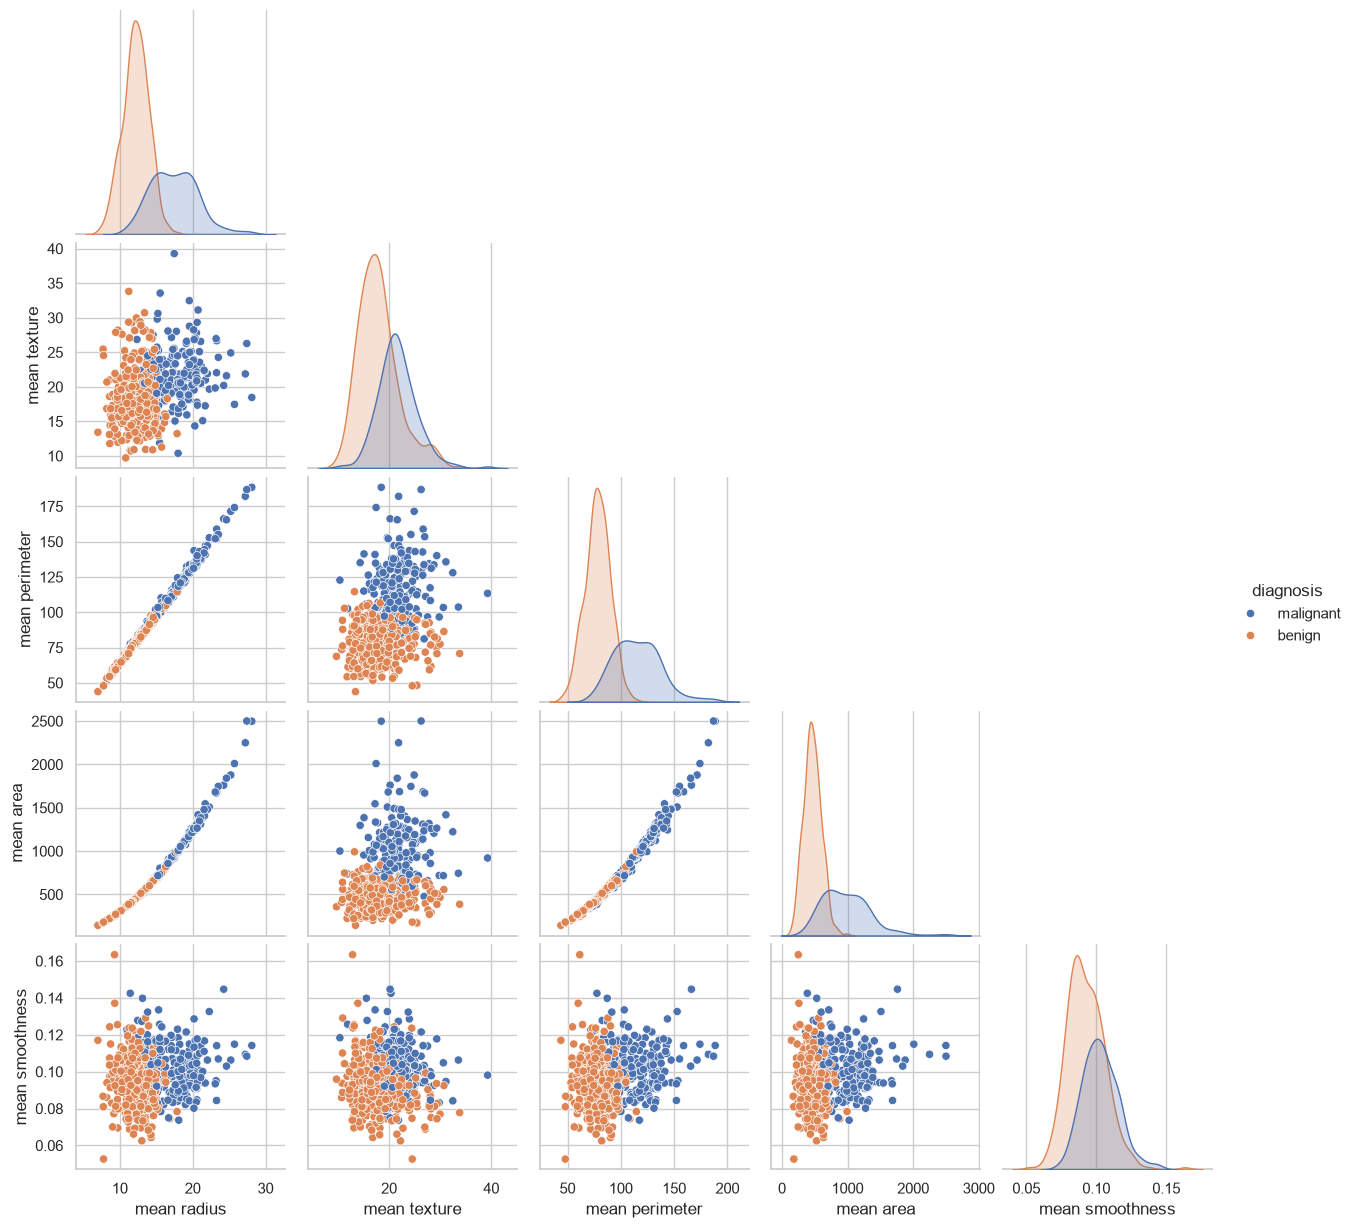

In [5]:
features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']
sns.pairplot(df[features + ['diagnosis']], hue='diagnosis', corner=True)
plt.show()

The two classes separate clearly for several features (e.g. mean radius, mean perimeter) — GaussianNB should do well.

## 3. Preprocessing

GaussianNB does not require scaling, but we scale anyway to keep comparability with other models.

In [6]:
X = cancer.data
y = cancer.target  # 0 = malignant, 1 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (426, 30)  Test: (143, 30)


## 4. Train Gaussian Naive Bayes

In [7]:
gnb = GaussianNB()
gnb.fit(X_train_s, y_train)
y_pred = gnb.predict(X_test_s)
y_prob = gnb.predict_proba(X_test_s)[:, 1]

print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'AUC     : {roc_auc_score(y_test, y_prob):.3f}')

Accuracy: 0.937
AUC     : 0.988


In [8]:
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.94      0.89      0.91        53
      benign       0.94      0.97      0.95        90

    accuracy                           0.94       143
   macro avg       0.94      0.93      0.93       143
weighted avg       0.94      0.94      0.94       143



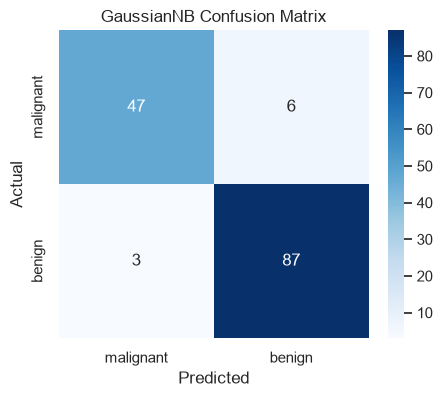

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('GaussianNB Confusion Matrix')
plt.show()

## 5. Predicted Probabilities

One advantage of NB: it outputs calibrated-ish probabilities per class.

In [10]:
proba = pd.DataFrame(gnb.predict_proba(X_test_s[:10]),
                        columns=['P(malignant)', 'P(benign)'])
proba['predicted'] = np.where(y_pred[:10] == 0, 'malignant', 'benign')
proba['actual'] = np.where(y_test[:10] == 0, 'malignant', 'benign')
proba.round(3)

,P(malignant),P(benign),predicted,actual
0,0.0,1.0,benign,benign
1,1.0,0.0,malignant,malignant
2,0.0,1.0,benign,benign
3,0.0,1.0,benign,benign
4,0.0,1.0,benign,malignant
5,1.0,0.0,malignant,malignant
6,1.0,0.0,malignant,malignant
7,1.0,0.0,malignant,malignant
8,1.0,0.0,malignant,malignant
9,0.0,1.0,benign,benign


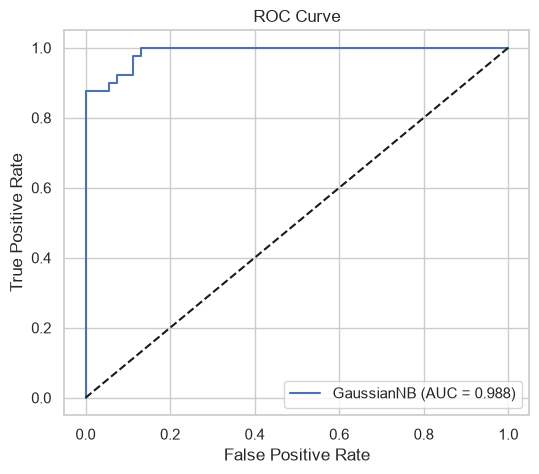

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'GaussianNB (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 6. Comparing Naive Bayes Variants

- **MultinomialNB** needs non-negative inputs → use raw (unscaled) features
- **BernoulliNB** binarises features at a threshold

In [12]:
results = {}

results['GaussianNB'] = accuracy_score(y_test, gnb.predict(X_test_s))

mnb = MultinomialNB().fit(X_train, y_train)
results['MultinomialNB (raw)'] = accuracy_score(y_test, mnb.predict(X_test))

bnb = BernoulliNB(binarize=0.5).fit(X_train_s, y_train)
results['BernoulliNB (scaled, binarize=0.5)'] = accuracy_score(y_test, bnb.predict(X_test_s))

pd.Series(results).round(3).to_frame('Test Accuracy')

,Test Accuracy
GaussianNB,0.937
MultinomialNB (raw),0.923
"BernoulliNB (scaled, binarize=0.5)",0.937


GaussianNB wins — the features are continuous measurements, exactly its use case.

## 7. Conclusion

- GaussianNB classifies breast tumours with **accuracy ≈ 0.94–0.96** and **AUC ≈ 0.99**.
- Extremely fast to train (no gradient descent, just mean/variance per class).
- The independence assumption is violated (many features are correlated), yet performance stays high.
- For medical screening the few **false negatives** (malignant missed) matter most — check the confusion matrix row for malignant.